In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import load_img, img_to_array
from sklearn.model_selection import train_test_split

In [2]:
BASE_DIR = r"C:\Users\ASUS\Desktop\Phone_screen CNN"

normal_path = os.path.join(BASE_DIR, "origin", "0", "Image_phones")
broken_path = os.path.join(BASE_DIR, "origin", "1", "Image_brokenphones")

AUG_DIR = os.path.join(BASE_DIR, "aug")

In [3]:
normal_images = os.listdir(normal_path)
broken_images = os.listdir(broken_path)

normal_images = [f for f in normal_images if f.lower().endswith((".jpg", ".jpeg", ".png"))]
broken_images = [f for f in broken_images if f.lower().endswith((".jpg", ".jpeg", ".png"))]

print("Normal images:", len(normal_images))
print("Cracked images:", len(broken_images))

Normal images: 34
Cracked images: 37


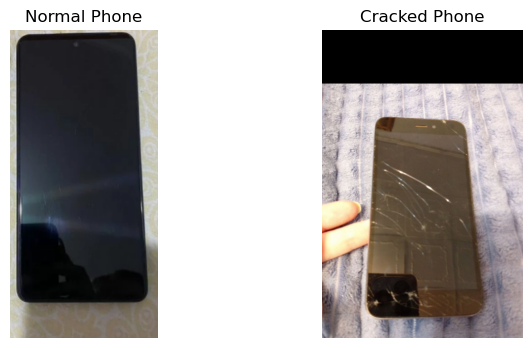

In [4]:
normal_img = load_img(os.path.join(normal_path, normal_images[0]))
broken_img = load_img(os.path.join(broken_path, broken_images[0]))

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(normal_img)
plt.title("Normal Phone")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(broken_img)
plt.title("Cracked Phone")
plt.axis("off")

plt.show()

In [5]:
image_paths = []
labels = []

for img in normal_images:
    image_paths.append(os.path.join(normal_path, img))
    labels.append(0)

for img in broken_images:
    image_paths.append(os.path.join(broken_path, img))
    labels.append(1)

X_train, X_val, y_train, y_val = train_test_split(
    image_paths, labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))


Training images: 56
Validation images: 15


In [6]:
train_normal_dir = os.path.join(AUG_DIR, "train", "0")
train_broken_dir = os.path.join(AUG_DIR, "train", "1")

val_normal_dir = os.path.join(BASE_DIR, "validation", "0")
val_broken_dir = os.path.join(BASE_DIR, "validation", "1")

os.makedirs(train_normal_dir, exist_ok=True)
os.makedirs(train_broken_dir, exist_ok=True)
os.makedirs(val_normal_dir, exist_ok=True)
os.makedirs(val_broken_dir, exist_ok=True)

print("Folders created!")

Folders created!


In [8]:
datagen = ImageDataGenerator(
    height_shift_range=0.2,
    width_shift_range=0.15,
    fill_mode="nearest"
)

for image_path, label in zip(X_train, y_train):

    img = load_img(image_path, target_size=(128, 128))
    img = img_to_array(img)
    img = np.expand_dims(img, axis=0)

    if label == 0:
        folder = train_normal_dir
    else:
        folder = train_broken_dir

    generator = datagen.flow(
        img,
        batch_size=1,
        save_to_dir=folder,
        save_prefix="image",
        save_format="png"
    )

    for i in range(5):
        next(generator)

print("Augmentation completed!")


Augmentation completed!


In [10]:
for path, label in zip(X_val, y_val):

    img = load_img(path)

    if label == 0:
        folder = val_normal_dir
    else:
        folder = val_broken_dir

    filename = os.path.basename(path)
    img.save(os.path.join(folder, filename))

print("Validation images saved!")

Validation images saved!


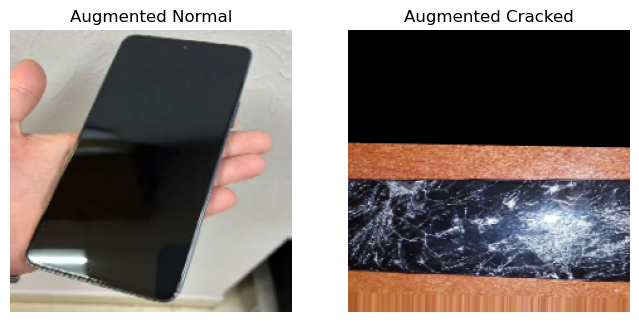

Normal augmented images: 321
Cracked augmented images: 339


In [11]:
normal_aug = os.listdir(train_normal_dir)
broken_aug = os.listdir(train_broken_dir)

img1 = load_img(os.path.join(train_normal_dir, normal_aug[0]))
img2 = load_img(os.path.join(train_broken_dir, broken_aug[0]))

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(img1)
plt.title("Augmented Normal")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img2)
plt.title("Augmented Cracked")
plt.axis("off")

plt.show()

print("Normal augmented images:", len(normal_aug))
print("Cracked augmented images:", len(broken_aug))